In [97]:
import numpy as np
import pandas as pd
import re

In [98]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [99]:
df = pd.read_csv('gurgaon_properties_13k_cleaned_v1.csv')

In [100]:
df.duplicated().sum()

np.int64(0)

In [101]:
df.drop_duplicates(inplace=True)

C:\Users\prama\AppData\Local\Temp\ipykernel_20188\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [102]:
df.reset_index(drop=True, inplace=True)

C:\Users\prama\AppData\Local\Temp\ipykernel_20188\1750890532.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


In [103]:
df.head(1)
# focus is on -> areaWithType, additionalRoom, agePossession, furnishDetails, features

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features
0,house,independent,sector 23,5.5,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,"pooja room,study room,servant room",3.0,East,5 to 10 Year Old,"['HUDA Sector 23 Market', 'Palam triangle', 'Palam Vihar Vyapar kendra', 'Ram Mandir', ""DR KAPOOR'S Dental Care and Implant Centre"", 'Metro Hospital and Heart Institute Gurgaon', 'Kalyan Hospital Gurgaon', 'Ansals plaza underground car parking', 'Ansals Plaza above ground car parking', 'HUDA sector 23 parking', 'Big Cinemas', 'Axis bank', 'Punjab national bank', 'Oriental bank of commerce', 'Moti Mahal', 'Pind Baluchi', 'Pizza Hut', ""Domino's Pizza"", 'Cafe Coffee Day', 'Om Sweets', ""McDonald's"", 'Masti ki Pathshala Teach India', 'Swiss Cottage school', 'Chiranjiv Bharati School', 'THE NORTHCAP UNIVERSITY', 'Palam vihar railway station', 'Bijwasan railway station']","['8 Wardrobe', '11 Fan', '1 Exhaust Fan', '18 Light', '1 Chimney', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Park', 'Natural Light', 'Spacious Interiors', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']"


## 1. areaWithType

In [104]:
df.sample(5)[['price','area','areaWithType']]

,price,area,areaWithType
5764,25.00,5800.0,Carpet area: 5800 (538.84 sq.m.)
2522,0.70,1200.0,Built Up area: 1200 (111.48 sq.m.)
12784,2.70,1935.0,Super Built up area 1935(179.77 sq.m.)
5380,2.33,2400.0,Super Built up area 2400(222.97 sq.m.)
6932,4.65,1836.0,Plot area 204(170.57 sq.m.)


In [105]:
# This function extracts the Super Built up area
def get_super_built_up_area(text):
    match = re.search(r'Super Built up area (\d+\.?\d*)', str(text))
    if match:
        return float(match.group(1))
    return None

In [106]:
# This function extracts the Built Up area or Carpet area
def get_area(text, area_type):
    match = re.search(area_type + r'\s*:\s*(\d+\.?\d*)', str(text))
    if match:
        return float(match.group(1))
    return None

In [107]:
# This function checks if the area is provided in sq.m. or sq.yards and converts it to sqft if needed
def convert_to_sqft(text, area_value):
    if area_value is None or pd.isna(area_value):
        return np.nan
    text = str(text)
    val_str = str(int(area_value)) if float(area_value).is_integer() else str(area_value)
    pattern = rf'{re.escape(val_str)}\s*(?:(sq\.ft\.|sq\.yards|sq\.m\.)\s*)?(?:\((\d+\.?\d*)\s*sq\.m\.\))?'
    match = re.search(pattern, text)
    if match:
        unit = match.group(1)
        sqm_str = match.group(2)
        if unit == 'sq.ft.':
            return float(area_value)
        elif unit == 'sq.yards':
            return round(float(sqm_str) * 10.7639) if sqm_str else round(float(area_value) * 9.0)
        elif unit == 'sq.m.':
            return round(float(area_value) * 10.7639)
        elif sqm_str:
            sqft_val = float(sqm_str) * 10.7639
            if abs(float(area_value) - sqft_val) / max(sqft_val, 1) < 0.05:
                return float(area_value)
            return round(sqft_val)
    if 'sq.m.' in text and '(' not in text and float(area_value) < 500:
        return round(float(area_value) * 10.7639)
    return float(area_value)

In [108]:
# Extract Super Built up area and convert to sqft if needed
df['super_built_up_area'] = df['areaWithType'].apply(get_super_built_up_area)
df['super_built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['super_built_up_area']), axis=1)

# Extract Built Up area and convert to sqft if needed
df['built_up_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Built Up area'))
df['built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['built_up_area']), axis=1)

# Extract Carpet area and convert to sqft if needed
df['carpet_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Carpet area'))
df['carpet_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['carpet_area']), axis=1)

In [109]:
df[['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].sample(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
3995,0.60,flat,800.0,Super Built up area 800(74.32 sq.m.)Carpet area: 550 sq.ft. (51.10 sq.m.),800.0,NaN,550.00
2967,12.50,house,3060.0,Plot area 470(392.98 sq.m.)Built Up area: 410 sq.yards (342.81 sq.m.)Carpet area: 340 sq.yards (284.28 sq.m.),NaN,3690.0,3060.00
5500,3.25,flat,3400.0,Super Built up area 3400(315.87 sq.m.)Carpet area: 2250 sq.ft. (209.03 sq.m.),3400.0,NaN,2250.00
1288,1.20,flat,1490.0,Super Built up area 1490(138.43 sq.m.)Carpet area: 1163.91 sq.ft. (108.13 sq.m.),1490.0,NaN,1163.91
6961,1.80,flat,1815.0,Super Built up area 1815(168.62 sq.m.)Carpet area: 1071.33 sq.ft. (99.53 sq.m.),1815.0,NaN,1071.33


In [110]:
df.duplicated().sum()

np.int64(0)

In [111]:
df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].shape

(2355, 7)

In [112]:
df[df['areaWithType'].str.contains('Plot')][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].head(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,5.50,house,2520.0,Plot area 280(234.12 sq.m.),NaN,NaN,NaN
6,6.40,house,3150.0,Plot area 350(292.64 sq.m.)Built Up area: 349 sq.yards (291.81 sq.m.)Carpet area: 348 sq.yards (290.97 sq.m.),NaN,3141.0,3132.0
10,6.80,house,2160.0,Plot area 240(200.67 sq.m.),NaN,NaN,NaN
15,6.25,house,22498.0,Plot area 3100(2591.99 sq.m.)Built Up area: 2660 sq.yards (2224.1 sq.m.)Carpet area: 2500 sq.yards (2090.32 sq.m.),NaN,23940.0,22500.0
25,8.50,house,2700.0,Plot area 300(250.84 sq.m.),NaN,NaN,NaN


In [113]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    28
price_per_sqft           28
area                     17
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom            0
floorNum                 22
facing                 2193
agePossession             1
nearbyLocations         280
furnishDetails         2844
features                710
super_built_up_area    5391
built_up_area          9911
carpet_area            5616
dtype: int64

In [114]:
all_nan_df = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].copy()

In [115]:
all_nan_df.head()

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,5.50,house,2520.0,Plot area 280(234.12 sq.m.),NaN,NaN,NaN
10,6.80,house,2160.0,Plot area 240(200.67 sq.m.),NaN,NaN,NaN
25,8.50,house,2700.0,Plot area 300(250.84 sq.m.),NaN,NaN,NaN
29,4.25,house,1836.0,Plot area 204(170.57 sq.m.),NaN,NaN,NaN
30,8.48,house,3600.0,Plot area 400(334.45 sq.m.),NaN,NaN,NaN


In [116]:
all_nan_index = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].index

In [117]:
# Function to extract plot area from 'areaWithType' column
def extract_plot_area(area_with_type):
    match = re.search(r'Plot area (\d+\.?\d*)', str(area_with_type))
    return float(match.group(1)) if match else None

In [118]:
all_nan_df['built_up_area'] = all_nan_df['areaWithType'].apply(extract_plot_area)

In [119]:
all_nan_df.head(10)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,5.50,house,2520.0,Plot area 280(234.12 sq.m.),NaN,280.0,NaN
10,6.80,house,2160.0,Plot area 240(200.67 sq.m.),NaN,240.0,NaN
25,8.50,house,2700.0,Plot area 300(250.84 sq.m.),NaN,300.0,NaN
29,4.25,house,1836.0,Plot area 204(170.57 sq.m.),NaN,204.0,NaN
30,8.48,house,3600.0,Plot area 400(334.45 sq.m.),NaN,400.0,NaN
52,1.20,house,900.0,Plot area 900(83.61 sq.m.),NaN,900.0,NaN
55,2.15,house,900.0,Plot area 100(83.61 sq.m.),NaN,100.0,NaN
56,0.80,house,675.0,Plot area 75(62.71 sq.m.),NaN,75.0,NaN
57,12.50,house,3240.0,Plot area 360(301.01 sq.m.),NaN,360.0,NaN
64,3.55,house,1449.0,Plot area 161(134.62 sq.m.),NaN,161.0,NaN


In [120]:
def convert_scale(row):
    text = row['areaWithType']
    raw_val = row['built_up_area']
    area_col = row['area']
    if pd.isna(raw_val):
        return area_col
    if pd.notna(area_col) and raw_val > 0:
        ratio = area_col / raw_val
        if 8.0 <= ratio <= 10.0:
            return raw_val * 9.0
        elif 10.0 < ratio <= 11.5:
            return round(raw_val * 10.7639)
    match = re.search(r'Plot area\s*\d+\.?\d*\s*\((\d+\.?\d*)\s*sq\.m\.\)', str(text))
    if match:
        sqft_from_sqm = float(match.group(1)) * 10.7639
        if abs(raw_val - sqft_from_sqm) / max(sqft_from_sqm, 1) < 0.05:
            return raw_val
        return round(sqft_from_sqm)
    return raw_val

In [121]:
all_nan_df['built_up_area'] = all_nan_df.apply(convert_scale, axis=1)

In [122]:
all_nan_df.head(10)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
0,5.50,house,2520.0,Plot area 280(234.12 sq.m.),NaN,2520.0,NaN
10,6.80,house,2160.0,Plot area 240(200.67 sq.m.),NaN,2160.0,NaN
25,8.50,house,2700.0,Plot area 300(250.84 sq.m.),NaN,2700.0,NaN
29,4.25,house,1836.0,Plot area 204(170.57 sq.m.),NaN,1836.0,NaN
30,8.48,house,3600.0,Plot area 400(334.45 sq.m.),NaN,3600.0,NaN
52,1.20,house,900.0,Plot area 900(83.61 sq.m.),NaN,900.0,NaN
55,2.15,house,900.0,Plot area 100(83.61 sq.m.),NaN,900.0,NaN
56,0.80,house,675.0,Plot area 75(62.71 sq.m.),NaN,675.0,NaN
57,12.50,house,3240.0,Plot area 360(301.01 sq.m.),NaN,3240.0,NaN
64,3.55,house,1449.0,Plot area 161(134.62 sq.m.),NaN,1449.0,NaN


In [123]:
# update the original dataframe
df.update(all_nan_df)

In [124]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    28
price_per_sqft           28
area                     17
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom            0
floorNum                 22
facing                 2193
agePossession             1
nearbyLocations         280
furnishDetails         2844
features                710
super_built_up_area    5391
built_up_area          8818
carpet_area            5616
dtype: int64

In [125]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,"pooja room,study room,servant room",3.0,East,5 to 10 Year Old,"['HUDA Sector 23 Market', 'Palam triangle', 'Palam Vihar Vyapar kendra', 'Ram Mandir', ""DR KAPOOR'S Dental Care and Implant Centre"", 'Metro Hospital and Heart Institute Gurgaon', 'Kalyan Hospital Gurgaon', 'Ansals plaza underground car parking', 'Ansals Plaza above ground car parking', 'HUDA sector 23 parking', 'Big Cinemas', 'Axis bank', 'Punjab national bank', 'Oriental bank of commerce', 'Moti Mahal', 'Pind Baluchi', 'Pizza Hut', ""Domino's Pizza"", 'Cafe Coffee Day', 'Om Sweets', ""McDonald's"", 'Masti ki Pathshala Teach India', 'Swiss Cottage school', 'Chiranjiv Bharati School', 'THE NORTHCAP UNIVERSITY', 'Palam vihar railway station', 'Bijwasan railway station']","['8 Wardrobe', '11 Fan', '1 Exhaust Fan', '18 Light', '1 Chimney', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Park', 'Natural Light', 'Spacious Interiors', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,2520.0,NaN
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet area: 1240.04 sq.ft. (115.2 sq.m.),3,3,3,servant room,6.0,South,1 to 5 Year Old,"[""V'Lante Mall"", 'NH 48 Gurugram', 'iGrow Montessori Play School', 'Matrikiran High School', 'Badsa AMS Hospital', 'GlobalHealthcare Multispeciality', 'Indira Gandhi International Airport', 'Patli Railway Station', 'Hyatt Regency', 'Nakhrola Stadium', 'Cricket Academy']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '1 Geyser', '12 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']",1900.0,NaN,1240.04
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,not available,6.0,North-West,1 to 5 Year Old,"['Sapphire 83 Mall', 'NH – 08', 'Knowledge Tree World School', 'DPG Institute of Technology', 'Genesis Hospital', 'Indira Gandhi International Airport', 'Sultanpur National Park', 'Imt Manesar', 'Heritage Village Resort & Spa', 'SkyJumper Trampoline Park']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '3 Geyser', '5 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Water purifier', 'Maintenance Staff', 'Water Storage', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']",2860.0,NaN,NaN
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,store room,4.0,West,1 to 5 Year Old,"['Sapphire 83 Mall', 'Dwarka Expressway', 'Ce

## 2. additionalRoom

In [126]:
df['additionalRoom'].value_counts()

additionalRoom
not available                                    5657
servant room                                     4286
study room                                        784
store room                                        630
servant room,store room                           519
study room,servant room                           496
others                                            223
pooja room                                        176
pooja room,servant room                           128
pooja room,study room,servant room                 76
pooja room,study room,servant room,store room      74
study room,servant room,store room                 62
pooja room,study room,servant room,others          57
servant room,others                                55
study room,store room                              54
servant room,pooja room                            38
pooja room,study room                              27
study room,others                                  26
pooja room,se

In [127]:
# additional room
# List of new columns to be created
new_cols = ['study room', 'servant room', 'store room', 'pooja room', 'others']

# Populate the new columns based on the "additionalRoom" column
for col in new_cols:
    df[col] = df['additionalRoom'].str.contains(col, na=False).astype(int)

In [128]:
df.sample(5)[['additionalRoom','study room', 'servant room', 'store room', 'pooja room', 'others']]

,additionalRoom,study room,servant room,store room,pooja room,others
12483,servant room,0,1,0,0,0
4253,not available,0,0,0,0,0
6150,"servant room,store room",0,1,1,0,0
10834,servant room,0,1,0,0,0
9108,not available,0,0,0,0,0


In [129]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,"pooja room,study room,servant room",3.0,East,5 to 10 Year Old,"['HUDA Sector 23 Market', 'Palam triangle', 'Palam Vihar Vyapar kendra', 'Ram Mandir', ""DR KAPOOR'S Dental Care and Implant Centre"", 'Metro Hospital and Heart Institute Gurgaon', 'Kalyan Hospital Gurgaon', 'Ansals plaza underground car parking', 'Ansals Plaza above ground car parking', 'HUDA sector 23 parking', 'Big Cinemas', 'Axis bank', 'Punjab national bank', 'Oriental bank of commerce', 'Moti Mahal', 'Pind Baluchi', 'Pizza Hut', ""Domino's Pizza"", 'Cafe Coffee Day', 'Om Sweets', ""McDonald's"", 'Masti ki Pathshala Teach India', 'Swiss Cottage school', 'Chiranjiv Bharati School', 'THE NORTHCAP UNIVERSITY', 'Palam vihar railway station', 'Bijwasan railway station']","['8 Wardrobe', '11 Fan', '1 Exhaust Fan', '18 Light', '1 Chimney', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Park', 'Natural Light', 'Spacious Interiors', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,2520.0,NaN,1,1,0,1,0
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet area: 1240.04 sq.ft. (115.2 sq.m.),3,3,3,servant room,6.0,South,1 to 5 Year Old,"[""V'Lante Mall"", 'NH 48 Gurugram', 'iGrow Montessori Play School', 'Matrikiran High School', 'Badsa AMS Hospital', 'GlobalHealthcare Multispeciality', 'Indira Gandhi International Airport', 'Patli Railway Station', 'Hyatt Regency', 'Nakhrola Stadium', 'Cricket Academy']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '1 Geyser', '12 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']",1900.0,NaN,1240.04,0,1,0,0,0
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,not available,6.0,North-West,1 to 5 Year Old,"['Sapphire 83 Mall', 'NH – 08', 'Knowledge Tree World School', 'DPG Institute of Technology', 'Genesis Hospital', 'Indira Gandhi International Airport', 'Sultanpur National Park', 'Imt Manesar', 'Heritage Village Resort & Spa', 'SkyJumper Trampoline Park']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '3 Geyser', '5 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Water purifier', 'Maintenance Staff', 'Water Storage', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']",2860.0,NaN,NaN,0,0,0,0,0
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+

## 3. agePossession

In [130]:
df['agePossession'].value_counts()

agePossession
1 to 5 Year Old       5016
0 to 1 Year Old       3156
5 to 10 Year Old      2038
Under Construction    1859
10+ Year Old           948
undefined              316
Within 6 months         67
Within 3 months         24
Dec 2023                20
By 2023                 17
By 2024                 16
Dec 2024                15
Mar 2024                12
Jan 2024                 7
Jun 2024                 7
Dec 2025                 7
Aug 2023                 6
Oct 2024                 6
Nov 2023                 5
Aug 2024                 5
Sep 2023                 4
By 2025                  4
Oct 2023                 4
Jul 2024                 3
Jan 2025                 3
Feb 2024                 3
Nov 2024                 3
May 2024                 3
Sep 2025                 2
Jul 2027                 2
Mar 2025                 2
Jun 2027                 2
Aug 2025                 2
Dec 2026                 2
Jul 2025                 2
Jan 2026                 2
By 2027       

In [131]:
def categorize_age_possession(value):
    if pd.isna(value):
        return "Undefined"
    if "0 to 1 Year Old" in value or "Within 6 months" in value or "Within 3 months" in value:
        return "New Property"
    if "1 to 5 Year Old" in value:
        return "Relatively New"
    if "5 to 10 Year Old" in value:
        return "Moderately Old"
    if "10+ Year Old" in value:
        return "Old Property"
    if "Under Construction" in value or "By" in value:
        return "Under Construction"
    try:
        # For entries like 'May 2024'
        int(value.split(" ")[-1])
        return "Under Construction"
    except:
        return "Undefined"

In [132]:
df['agePossession'] = df['agePossession'].apply(categorize_age_possession)

In [133]:
df['agePossession'].value_counts()

agePossession
Relatively New        5016
New Property          3247
Under Construction    2039
Moderately Old        2038
Old Property           948
Undefined              317
Name: count, dtype: int64

In [134]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,"pooja room,study room,servant room",3.0,East,Moderately Old,"['HUDA Sector 23 Market', 'Palam triangle', 'Palam Vihar Vyapar kendra', 'Ram Mandir', ""DR KAPOOR'S Dental Care and Implant Centre"", 'Metro Hospital and Heart Institute Gurgaon', 'Kalyan Hospital Gurgaon', 'Ansals plaza underground car parking', 'Ansals Plaza above ground car parking', 'HUDA sector 23 parking', 'Big Cinemas', 'Axis bank', 'Punjab national bank', 'Oriental bank of commerce', 'Moti Mahal', 'Pind Baluchi', 'Pizza Hut', ""Domino's Pizza"", 'Cafe Coffee Day', 'Om Sweets', ""McDonald's"", 'Masti ki Pathshala Teach India', 'Swiss Cottage school', 'Chiranjiv Bharati School', 'THE NORTHCAP UNIVERSITY', 'Palam vihar railway station', 'Bijwasan railway station']","['8 Wardrobe', '11 Fan', '1 Exhaust Fan', '18 Light', '1 Chimney', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Park', 'Natural Light', 'Spacious Interiors', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,2520.0,NaN,1,1,0,1,0
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet area: 1240.04 sq.ft. (115.2 sq.m.),3,3,3,servant room,6.0,South,Relatively New,"[""V'Lante Mall"", 'NH 48 Gurugram', 'iGrow Montessori Play School', 'Matrikiran High School', 'Badsa AMS Hospital', 'GlobalHealthcare Multispeciality', 'Indira Gandhi International Airport', 'Patli Railway Station', 'Hyatt Regency', 'Nakhrola Stadium', 'Cricket Academy']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '1 Geyser', '12 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']",1900.0,NaN,1240.04,0,1,0,0,0
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,not available,6.0,North-West,Relatively New,"['Sapphire 83 Mall', 'NH – 08', 'Knowledge Tree World School', 'DPG Institute of Technology', 'Genesis Hospital', 'Indira Gandhi International Airport', 'Sultanpur National Park', 'Imt Manesar', 'Heritage Village Resort & Spa', 'SkyJumper Trampoline Park']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '3 Geyser', '5 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Water purifier', 'Maintenance Staff', 'Water Storage', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']",2860.0,NaN,NaN,0,0,0,0,0
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,sto

## 4. furnishDetails

In [135]:
df.sample(5)[['furnishDetails','features']]

,furnishDetails,features
9826,"['1 AC', '1 Chimney', '1 Fan', '1 Geyser', '1 Light', '1 Microwave', '1 Wardrobe', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Modular Kitchen', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Maintenance Staff', 'Water Storage', 'Waste Disposal', 'Rain Water Harvesting', 'Feng Shui / Vaastu Compliant', 'Park', 'Piped-gas', 'Visitor Parking', 'Water purifier']"
7980,"['1 Chimney', '1 Exhaust Fan', '1 Fan', '1 Geyser', '1 Modular Kitchen', '1 Light', '1 Wardrobe', '1 Water Purifier', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine']","['High Ceiling Height', 'Maintenance Staff', 'Fitness Centre / GYM', 'Water Storage', 'Waste Disposal', 'Rain Water Harvesting', 'Security / Fire Alarm', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Club house / Community Center', 'Feng Shui / Vaastu Compliant', 'Park', 'Security Personnel', 'Natural Light', 'Intercom Facility', 'Lift(s)', 'Water purifier']"
2131,"['1 Fan', '1 Geyser', '1 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']","['Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Natural Light', 'Airy Rooms', 'Internet/wi-fi connectivity', 'Spacious Interiors', 'Water softening plant']"
4759,NaN,NaN
12090,NaN,"['Club house / Community Center', 'Fitness Centre / GYM', 'Intercom Facility', 'Lift(s)', 'Swimming Pool', 'Shopping Centre', 'Park', 'Maintenance Staff', 'Visitor Parking', 'Water Storage', 'Feng Shui / Vaastu Compliant', 'Security / Fire Alarm']"


In [136]:
# Extract all unique furnishings from the furnishDetails column
all_furnishings = []
for detail in df['furnishDetails'].dropna():
    furnishings = detail.replace('[', '').replace(']', '').replace("'", "").split(', ')
    all_furnishings.extend(furnishings)
unique_furnishings = list(set(all_furnishings))

In [137]:
# Define a function to extract the count of a furnishing from the furnishDetails
def get_furnishing_count(details, furnishing):
    if isinstance(details, str):
        if f"No {furnishing}" in details:
            return 0
        pattern = re.compile(rf"(\d+) {re.escape(furnishing)}\b")
        match = pattern.search(details)
        if match:
            return int(match.group(1))
        elif re.search(rf"\b{re.escape(furnishing)}\b", details):
            return 1
    return 0

In [138]:
# Simplify the furnishings list by removing "No" prefix and numbers (sorted for reproducibility)
columns_to_include = [re.sub(r'No |\d+', '', furnishing).strip() for furnishing in unique_furnishings]
columns_to_include = sorted(list(set(furnishing for furnishing in columns_to_include if furnishing)))

In [139]:
# Create new columns for each unique furnishing and populate with counts
for furnishing in columns_to_include:
    df[furnishing] = df['furnishDetails'].apply(lambda x: get_furnishing_count(x, furnishing))

In [140]:
# Create the new dataframe with the required columns
furnishings_df = df[['furnishDetails'] + columns_to_include].copy()

In [141]:
furnishings_df.shape

(13605, 19)

In [142]:
furnishings_df.drop(columns=['furnishDetails'],inplace=True)

C:\Users\prama\AppData\Local\Temp\ipykernel_20188\114705885.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  furnishings_df.drop(columns=['furnishDetails'],inplace=True)


In [143]:
furnishings_df.sample(5)

,AC,Bed,Chimney,Curtains,Dining Table,Exhaust Fan,Fan,Fridge,Geyser,Light,Microwave,Modular Kitchen,Sofa,Stove,TV,Wardrobe,Washing Machine,Water Purifier
421,0,0,0,0,0,0,6,0,0,6,0,0,0,0,0,0,0,0
378,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12373,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1
9309,1,0,1,0,0,0,1,0,0,1,0,1,0,0,0,1,0,0
5574,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


In [144]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [145]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(furnishings_df)

In [146]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss_reduced.append(kmeans.inertia_)

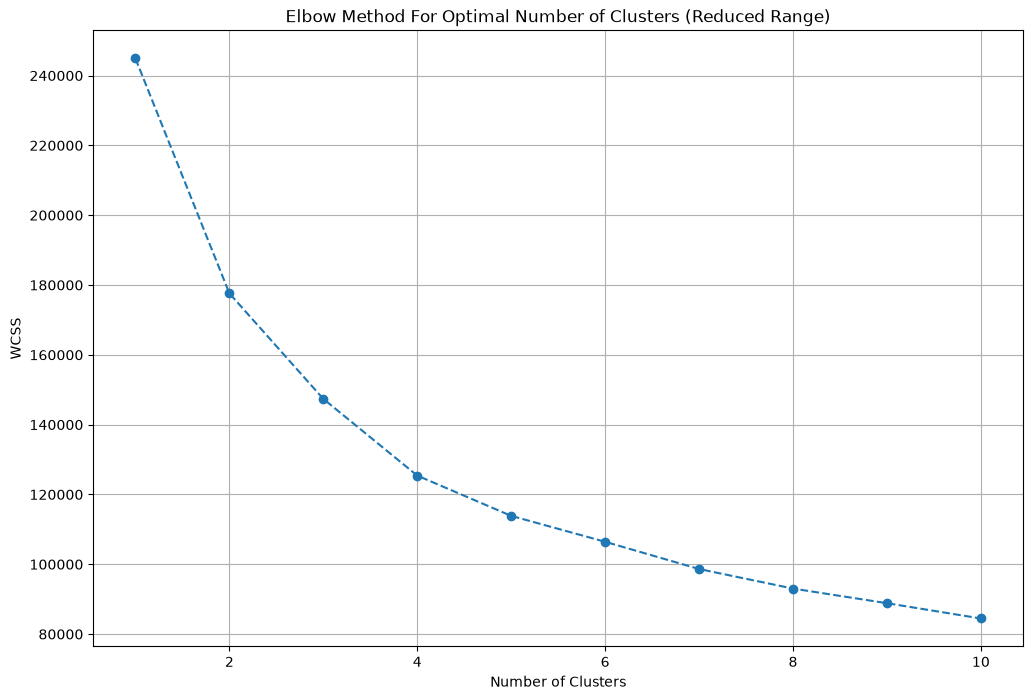

In [147]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [148]:
n_clusters = 3

# Fit the KMeans model
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
raw_clusters = kmeans.fit_predict(scaled_data)

In [149]:
# Order cluster labels by ascending mean item count: 0 -> unfurnished, 1 -> semifurnished, 2 -> furnished
cluster_order = furnishings_df.groupby(raw_clusters).mean().sum(axis=1).sort_values().index.tolist()
cluster_map = {old_id: new_id for new_id, old_id in enumerate(cluster_order)}
cluster_assignments = pd.Series(raw_clusters, index=df.index).map(cluster_map).values

In [150]:
df.drop(columns=columns_to_include, inplace=True)

C:\Users\prama\AppData\Local\Temp\ipykernel_20188\1772979548.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=columns_to_include, inplace=True)


In [151]:
df['furnishing_type'] = cluster_assignments

In [152]:
df.sample(5)[['furnishDetails','furnishing_type']]
# 0 -> unfurnished
# 1 -> semifurnished
# 2 -> furnished

,furnishDetails,furnishing_type
769,"['1 Exhaust Fan', '10 Light', '4 AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0
13578,"['1 AC', '1 Chimney', '1 Modular Kitchen', '1 Light', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0
4869,"['1 AC', '1 Bed', '1 Chimney', '1 Curtains', '1 Dining Table', '1 Exhaust Fan', '1 Fan', '1 Geyser', '1 Modular Kitchen', '1 Light', '1 Microwave', '1 Fridge', '1 Sofa', '1 Stove', '1 TV', '1 Wardrobe', '1 Washing Machine', '1 Water Purifier']",2
4427,"['1 AC', '1 Bed', '1 Chimney', '1 Curtains', '1 Dining Table', '1 Exhaust Fan', '1 Fan', '1 Geyser', '1 Modular Kitchen', '1 Light', '1 Microwave', '1 Fridge', '1 Sofa', '1 Stove', '1 TV', '1 Wardrobe', '1 Washing Machine', '1 Water Purifier']",2
2419,NaN,0


## 5. features

In [153]:
df[['society','features']].sample(5)

,society,features
8188,indiabulls enigma,"['Fitness Centre / GYM', 'Maintenance Staff', 'Water Storage', 'Rain Water Harvesting', 'Security / Fire Alarm', 'Visitor Parking', 'Swimming Pool', 'Power Back-up', 'Club house / Community Center', 'Feng Shui / Vaastu Compliant', 'Park', 'Intercom Facility', 'Lift(s)']"
1320,paras dews,"['Centrally Air Conditioned', 'Water purifier', 'Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Piped-gas', 'Internet/wi-fi connectivity', 'Recently Renovated', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Low Density Society', 'Waste Disposal', 'Rain Water Harvesting', 'Water softening plant', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"
5158,sobha city,"['Shopping Centre', 'Maintenance Staff', 'Fitness Centre / GYM', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Waste Disposal', 'Rain Water Harvesting', 'Security / Fire Alarm', 'Visitor Parking', 'Swimming Pool', 'Club house / Community Center', 'Feng Shui / Vaastu Compliant', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Intercom Facility', 'Spacious Interiors', 'Water softening plant', 'Lift(s)', 'Water purifier', 'Low Density Society']"
2016,signature andour heights,"['Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Piped-gas', 'Visitor Parking', 'Natural Light', 'Internet/wi-fi connectivity', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting']"
4275,shapoorji pallonji joyville gurugram,"['Maintenance Staff', 'Water Storage', 'Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Park', 'Visitor Parking', 'Intercom Facility', 'Lift(s)']"


In [154]:
df['features'].isnull().sum()

np.int64(710)

In [155]:
temp_df = df[df['features'].isnull()]
temp_df.shape

(710, 26)

In [156]:
import os
# 1. Impute from appartments.csv if available
if os.path.exists('appartments.csv'):
    app_df = pd.read_csv('appartments.csv')
    app_df['PropertyName'] = app_df['PropertyName'].astype(str).str.strip().str.lower()
    x = temp_df.merge(app_df, left_on=temp_df['society'].astype(str).str.strip().str.lower(), right_on='PropertyName', how='left')['TopFacilities']
    df.loc[temp_df.index, 'features'] = x.values

# 2. Fallback: impute remaining missing features using the mode of the same society within df
temp_df_rem = df[df['features'].isnull()]
society_features_map = (
    df[df['features'].notnull() & ~df['society'].astype(str).str.strip().str.lower().isin(['independent', 'not applicable', 'nan'])]
    .groupby(df['society'].astype(str).str.strip().str.lower())['features']
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0])
)
df.loc[temp_df_rem.index, 'features'] = temp_df_rem['society'].astype(str).str.strip().str.lower().map(society_features_map).values

In [157]:
df['features'].isnull().sum()

np.int64(379)

In [158]:
from sklearn.preprocessing import MultiLabelBinarizer
import ast

In [159]:
# Convert the string representation of lists in the 'features' column to actual lists
df['features_list'] = df['features'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) and str(x).startswith('[') else [])

# Use MultiLabelBinarizer to convert the features list into a binary matrix
mlb = MultiLabelBinarizer()
features_binary_matrix = mlb.fit_transform(df['features_list'])

# Convert the binary matrix into a DataFrame
features_binary_df = pd.DataFrame(features_binary_matrix, columns=mlb.classes_)

In [160]:
features_binary_df.sample(5)

,24/7 Power Backup,24/7 Water Supply,24x7 Security,ATM,Acupressure Park,Aerobics Centre,Air Hockey,Airy Rooms,Amphitheatre,Automated Car Wash,Badminton Court,Bank Attached Property,Banquet Hall,Bar/Chill-Out Lounge,Barbecue,Basketball Court,Beach Volley Ball Court,Billiards,Bowling Alley,Bus Shelter,Business Lounge,CCTV Camera Security,Cafeteria,Car Parking,Car wash area,Card Room,Centrally Air Conditioned,Changing Area,Children's Play Area,Cigar Lounge,Clinic,Club House,Club house / Community Center,Community Hall,Concierge Service,Conference room,Creche/Day care,Cricket Pitch,Doctor on Call,Earthquake Resistant,Entrance Lobby,False Ceiling Lighting,Feng Shui / Vaastu Compliant,Fire Fighting Systems,Fitness Centre / GYM,Flower Garden,Food Court,Foosball,Football,Fountain,Gated Community,Gazebo,Golf Course,Grocery Shop,Gymnasium,High Ceiling Height,High Speed Elevators,Infinity Pool,Intercom Facility,Internal Street Lights,Internet/wi-fi connectivity,Jacuzzi,Jogging Track,Landscape Garden,Laundry,Lawn Tennis Court,Library,Lift(s),Lounge,Low Density Society,Maintenance Staff,Manicured Garden,Medical Centre,Milk Booth,Mini Theatre,Multipurpose Court,Multipurpose Hall,Natural Light,Natural Pond,No open drainage around,Park,Party Lawn,Pergola,Piped Gas,Piped-gas,Pool Table,Power Back up Lift,Power Back-up,Private Garden / Terrace,Property Staff,RO System,Rain Water Harvesting,Reading Lounge,Recently Renovated,Reflexology Park,Restaurant,Salon,Sauna,School,Security / Fire Alarm,Security Personnel,Separate entry for servant room,Sewage Treatment Plant,Shopping Centre,Skating Rink,Solar Lighting,Solar Water Heating,Spa,Spacious Interiors,Squash Court,Steam Room,Sun Deck,Swimming Pool,Table Tennis,Temple,Terrace Garden,Theater Home,Theatre,Toddler Pool,Valet Parking,Vastu Compliant,Video Door Security,Visitor Parking,Visitors Parking,Volley Ball Court,Waiting Lounge,Waste Disposal,Water Softener Plant,Water Storage,Water purifier,Water softening plant,Wi-Fi Connectivity,Yoga/Meditation Area
2161,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
12884,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0
4287,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0
4859,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0
4074,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0


In [161]:
features_binary_df.shape

(13605, 133)

In [162]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(features_binary_df)
    wcss_reduced.append(kmeans.inertia_)

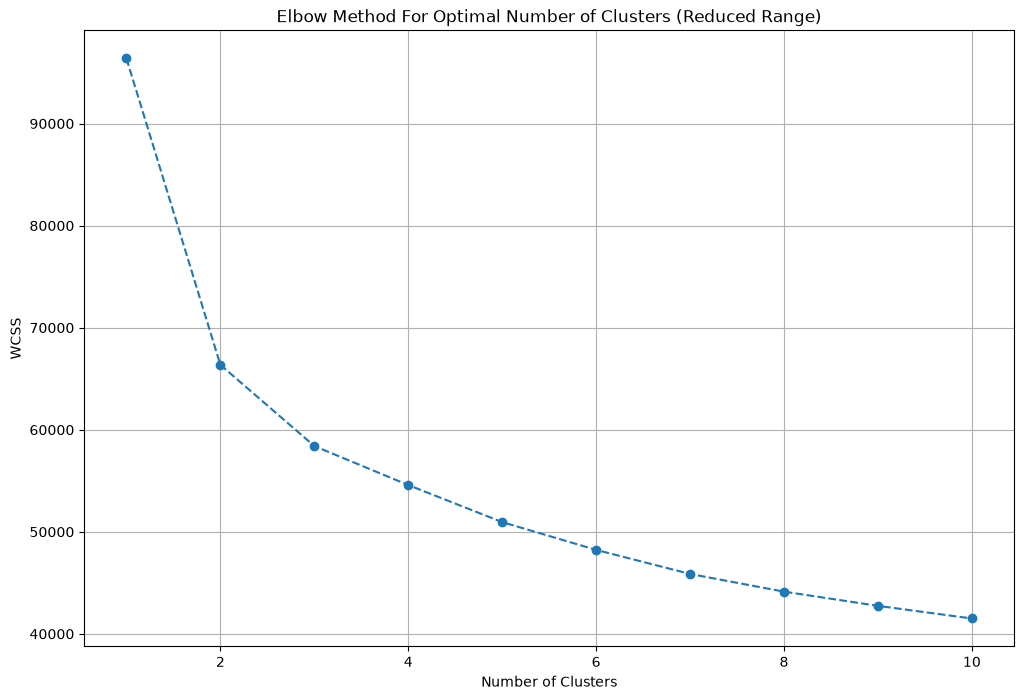

In [163]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [164]:
# Define the weights for all 130 features (105 original + 25 missing features)
weights = {
    '24/7 Power Backup': 8, '24/7 Water Supply': 4, '24x7 Security': 7, 'ATM': 4,
    'Aerobics Centre': 6, 'Airy Rooms': 8, 'Amphitheatre': 7, 'Badminton Court': 7,
    'Banquet Hall': 8, 'Bar/Chill-Out Lounge': 9, 'Barbecue': 7, 'Basketball Court': 7,
    'Billiards': 7, 'Bowling Alley': 8, 'Business Lounge': 9, 'CCTV Camera Security': 8,
    'Cafeteria': 6, 'Car Parking': 6, 'Card Room': 6, 'Centrally Air Conditioned': 9,
    'Changing Area': 6, "Children's Play Area": 7, 'Cigar Lounge': 9, 'Clinic': 5,
    'Club House': 9, 'Concierge Service': 9, 'Conference room': 8, 'Creche/Day care': 7,
    'Cricket Pitch': 7, 'Doctor on Call': 6, 'Earthquake Resistant': 5, 'Entrance Lobby': 7,
    'False Ceiling Lighting': 6, 'Feng Shui / Vaastu Compliant': 5, 'Fire Fighting Systems': 8,
    'Fitness Centre / GYM': 8, 'Flower Garden': 7, 'Food Court': 6, 'Foosball': 5,
    'Football': 7, 'Fountain': 7, 'Gated Community': 7, 'Golf Course': 10, 'Grocery Shop': 6,
    'Gymnasium': 8, 'High Ceiling Height': 8, 'High Speed Elevators': 8, 'Infinity Pool': 9,
    'Intercom Facility': 7, 'Internal Street Lights': 6, 'Internet/wi-fi connectivity': 7,
    'Jacuzzi': 9, 'Jogging Track': 7, 'Landscape Garden': 8, 'Laundry': 6,
    'Lawn Tennis Court': 8, 'Library': 8, 'Lounge': 8, 'Low Density Society': 7,
    'Maintenance Staff': 6, 'Manicured Garden': 7, 'Medical Centre': 5, 'Milk Booth': 4,
    'Mini Theatre': 9, 'Multipurpose Court': 7, 'Multipurpose Hall': 7, 'Natural Light': 8,
    'Natural Pond': 7, 'Park': 8, 'Party Lawn': 8, 'Piped Gas': 7, 'Pool Table': 7,
    'Power Back up Lift': 8, 'Private Garden / Terrace': 9, 'Property Staff': 7,
    'RO System': 7, 'Rain Water Harvesting': 7, 'Reading Lounge': 8, 'Restaurant': 8,
    'Salon': 8, 'Sauna': 9, 'Security / Fire Alarm': 9, 'Security Personnel': 9,
    'Separate entry for servant room': 8, 'Sewage Treatment Plant': 6, 'Shopping Centre': 7,
    'Skating Rink': 7, 'Solar Lighting': 6, 'Solar Water Heating': 7, 'Spa': 9,
    'Spacious Interiors': 9, 'Squash Court': 8, 'Steam Room': 9, 'Sun Deck': 8,
    'Swimming Pool': 8, 'Temple': 5, 'Theatre': 9, 'Toddler Pool': 7, 'Valet Parking': 9,
    'Video Door Security': 9, 'Visitor Parking': 7, 'Water Softener Plant': 7,
    'Water Storage': 7, 'Water purifier': 7, 'Yoga/Meditation Area': 7,
    'Lift(s)': 8, 'Club house / Community Center': 9, 'Piped-gas': 7,
    'Water softening plant': 7, 'Power Back-up': 8, 'Waste Disposal': 6,
    'No open drainage around': 6, 'Recently Renovated': 6, 'Bank Attached Property': 5,
    'Gazebo': 7, 'Terrace Garden': 8, 'Vastu Compliant': 5, 'Wi-Fi Connectivity': 7,
    'Reflexology Park': 7, 'Bus Shelter': 4, 'Visitors Parking': 7, 'Car wash area': 5,
    'Community Hall': 7, 'Automated Car Wash': 6, 'Waiting Lounge': 6, 'Pergola': 6,
    'Air Hockey': 5, 'Volley Ball Court': 7, 'Beach Volley Ball Court': 7, 'School': 6
}

In [165]:
# Calculate luxury score across all binary feature columns
luxury_score = features_binary_df.apply(
    lambda row: sum(row[col] * weights.get(col, 5) for col in features_binary_df.columns), axis=1
)

In [166]:
df['luxury_score'] = luxury_score

In [167]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,features_list,luxury_score
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,"pooja room,study room,servant room",3.0,East,Moderately Old,"['HUDA Sector 23 Market', 'Palam triangle', 'Palam Vihar Vyapar kendra', 'Ram Mandir', ""DR KAPOOR'S Dental Care and Implant Centre"", 'Metro Hospital and Heart Institute Gurgaon', 'Kalyan Hospital Gurgaon', 'Ansals plaza underground car parking', 'Ansals Plaza above ground car parking', 'HUDA sector 23 parking', 'Big Cinemas', 'Axis bank', 'Punjab national bank', 'Oriental bank of commerce', 'Moti Mahal', 'Pind Baluchi', 'Pizza Hut', ""Domino's Pizza"", 'Cafe Coffee Day', 'Om Sweets', ""McDonald's"", 'Masti ki Pathshala Teach India', 'Swiss Cottage school', 'Chiranjiv Bharati School', 'THE NORTHCAP UNIVERSITY', 'Palam vihar railway station', 'Bijwasan railway station']","['8 Wardrobe', '11 Fan', '1 Exhaust Fan', '18 Light', '1 Chimney', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Park', 'Natural Light', 'Spacious Interiors', 'Fitness Centre / GYM', 'Waste Disposal', 'Club house / Community Center']",NaN,2520.0,NaN,1,1,0,1,0,1,"[Feng Shui / Vaastu Compliant, Private Garden / Terrace, High Ceiling Height, False Ceiling Lighting, Water Storage, Separate entry for servant room, No open drainage around, Piped-gas, Park, Natural Light, Spacious Interiors, Fitness Centre / GYM, Waste Disposal, Club house / Community Center]",104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet area: 1240.04 sq.ft. (115.2 sq.m.),3,3,3,servant room,6.0,South,Relatively New,"[""V'Lante Mall"", 'NH 48 Gurugram', 'iGrow Montessori Play School', 'Matrikiran High School', 'Badsa AMS Hospital', 'GlobalHealthcare Multispeciality', 'Indira Gandhi International Airport', 'Patli Railway Station', 'Hyatt Regency', 'Nakhrola Stadium', 'Cricket Academy']","['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '1 Geyser', '12 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']",1900.0,NaN,1240.04,0,1,0,0,0,1,"[Security / Fire Alarm, Power Back-up, Feng Shui / Vaastu Compliant, Lift(s), High Ceiling Height, Maintenance Staff, Separate entry for servant room, No open drainage around, Bank Attached Property, Visitor Parking, Swimming Pool, Park, Natural Light, Airy Rooms, Shopping Centre, Fitness Centre / GYM, Waste Disposal, Rain Water Harvesting, Club house / Community Center, Water softening plant]",146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,not available,6.0,North-West,Relatively New,"['Sapphire 83 Mall', 'NH – 08', 'Knowledge Tree World School', 'DPG Institute of Technology', 'Genesis Hospital', 'Indira Gandhi International Airport', 'Sultanpur National Park', 'Imt Manesar', 'Heritage 

In [168]:
# cols to drop -> nearbyLocations, furnishDetails, features, features_list, additionalRoom
df.drop(columns=['nearbyLocations', 'furnishDetails', 'features', 'features_list', 'additionalRoom'], inplace=True)

C:\Users\prama\AppData\Local\Temp\ipykernel_20188\3556110750.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['nearbyLocations', 'furnishDetails', 'features', 'features_list', 'additionalRoom'], inplace=True)


In [170]:
df.sample(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
11892,flat,ireo victory valley,sector 67,3.25,13254.0,2452.0,Super Built up area 2452(227.80 sq.m.),3,4,3+,9.0,North-East,Relatively New,2452.0,NaN,NaN,0,0,0,0,0,0,57
2674,house,palam vihar extension west zone rwa,sector 2,0.40,4444.0,900.0,Plot area 900(83.61 sq.m.),6,4,2,2.0,West,Moderately Old,NaN,900.0,NaN,0,0,0,0,0,0,36
3811,flat,emaar the palm springs,sector 54,9.60,24704.0,3886.0,Super Built up area 3886(361.02 sq.m.),4,6,3+,12.0,East,Moderately Old,3886.0,NaN,NaN,0,1,0,0,0,2,145
860,house,independent,sector 46,5.65,23870.0,2367.0,Plot area 263(219.9 sq.m.),8,6,3+,3.0,South-West,Moderately Old,NaN,2367.0,NaN,0,1,0,0,0,1,73
3502,house,project housing board colony,sector 28,2.58,17695.0,1458.0,Carpet area: 1300 (120.77 sq.m.),4,2,2,2.0,NaN,Undefined,NaN,NaN,1300.0,0,0,0,0,0,0,0


In [171]:
df.shape

(13605, 23)

In [172]:
df.duplicated().sum()

np.int64(16)

In [173]:
df.drop_duplicates(inplace=True)

C:\Users\prama\AppData\Local\Temp\ipykernel_20188\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [174]:
df.shape

(13589, 23)

In [175]:
df.to_csv('gurgaon_properties_13k_cleaned_v2.csv', index=False)